# 03 · VAE architecture, training and threshold calibration

A Variational Autoencoder written from scratch with `torch.nn`: no pretrained models and no VAE libraries. The code lives in `src/models/vae.py`, `src/training/losses.py` and `src/training/train.py`.

## 1. Mathematical formulation

**Generative model:**
- prior $p(z) = \mathcal{N}(0, I)$
- decoder $p_\theta(x \mid z) = \mathcal{N}\big(x;\ \hat{x}_\theta(z),\ I\big)$, over the 29 standardised features

**Approximate posterior (encoder):** $q_\phi(z \mid x) = \mathcal{N}\big(z;\ \mu_\phi(x),\ \operatorname{diag}(\sigma^2_\phi(x))\big)$. The network outputs $\log\sigma^2$ rather than $\sigma^2$: it is unconstrained, numerically stable, and clamped to $[-10, 10]$.

**Evidence lower bound (ELBO):**
$$\log p_\theta(x) \;\ge\; \underbrace{\mathbb{E}_{q_\phi(z\mid x)}\big[\log p_\theta(x\mid z)\big]}_{\text{reconstruction}} \;-\; \underbrace{\mathrm{KL}\big(q_\phi(z\mid x)\,\|\,p(z)\big)}_{\text{regularisation}}$$

**Training loss** (per transaction, minimised and averaged over the batch):
$$\mathcal{L}(x) = \underbrace{\tfrac12\lVert x-\hat x\rVert^2}_{\text{reconstruction (MSE summed over features)}} + \beta\,\underbrace{\Big(-\tfrac12\sum_{k}\big(1+\log\sigma_k^2-\mu_k^2-\sigma_k^2\big)\Big)}_{\text{closed-form KL}}$$

**Reparameterization trick:** $z = \mu + \sigma \odot \varepsilon$, with $\varepsilon \sim \mathcal{N}(0, I)$. The randomness sits in $\varepsilon$, so gradients flow through $\mu$ and $\sigma$ and the whole model trains with ordinary back-propagation.

**Role of each component:**

| Component | Role |
|---|---|
| Encoder → $(\mu, \log\sigma^2)$ | Maps a transaction to a *distribution* over latent codes, not a single point |
| Reparameterization | Makes sampling differentiable |
| Decoder → $\hat x$ | Maps a latent code back to the feature space; decoding $z \sim p(z)$ generates new samples |
| Reconstruction term | Rewards faithful reconstruction. With a unit-variance Gaussian decoder this is the negative log-likelihood up to a constant, i.e. an MSE summed over features. Summing (rather than averaging) keeps it on the ELBO's scale; averaging would down-weight reconstruction 14.5× relative to KL. |
| KL term | Pulls each posterior towards the prior, so the latent space is smooth and sampling from $p(z)$ gives realistic decodes |
| $\beta$ and warm-up | $\beta$ rises linearly from 0.1 to 1 over the first 10 epochs, to reduce posterior collapse; after that $\beta = 1$ (the standard ELBO) |

**Anomaly score:** reconstruction error $\frac{1}{29}\lVert x - \hat x_\theta(\mu_\phi(x))\rVert^2$. It is a distance, **not** a fraud probability.

In [1]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_ROOT = Path("/content/drive/MyDrive/genAI")  # change this if the project folder lives elsewhere on Drive
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECT_ROOT = PROJECT_ROOT.resolve()
os.environ.setdefault("MPLCONFIGDIR", str(PROJECT_ROOT / ".cache" / "matplotlib"))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT.name)

Project root: genAI


In [2]:
import numpy as np
import pandas as pd
import torch
import yaml
import matplotlib.pyplot as plt

from src.data.prepare import load_experiment_inputs
from src.evaluation import model_plots as mp
from src.evaluation.plots import apply_style
from src.models.vae import VAE, VAEConfig
from src.training.losses import kl_divergence, vae_loss
from src.training.run import load_experiment_config, read_run, run_dir, train_one
from src.utils.io import load_config

pd.set_option("display.width", 200)
apply_style()
data_cfg = load_config(PROJECT_ROOT)
e1_cfg = load_experiment_config(PROJECT_ROOT, "e1_primary")
e2_cfg = load_experiment_config(PROJECT_ROOT, "e2_unsupervised")
print(yaml.safe_dump({k: e1_cfg[k] for k in ("model", "training", "threshold", "seeds", "device")}, sort_keys=False))

model:
  input_dim: 29
  hidden_dims:
  - 64
  - 32
  latent_dim: 8
  activation: leaky_relu
  logvar_clamp:
  - -10.0
  - 10.0
training:
  batch_size: 512
  learning_rate: 0.001
  weight_decay: 0.0
  max_epochs: 300
  early_stopping_patience: 10
  kl_warmup_epochs: 10
  beta: 1.0
  grad_clip_norm: 5.0
  val_noise_seed: 1234
threshold:
  method: validation_percentile
  percentile: 99.0
seeds:
- 0
- 1
- 2
- 3
- 4
device: cpu



## 2. Architecture (configurable: hidden sizes, latent dimension and activation come from the YAML config)

In [3]:
model = VAE(VAEConfig.from_dict(e1_cfg["model"]))
print(model)
layers = [(name, tuple(p.shape), p.numel()) for name, p in model.named_parameters()]
print(f"Total parameters: {model.n_parameters():,}")
pd.DataFrame(layers, columns=["parameter", "shape", "count"])

VAE(
  (encoder): Encoder(
    (trunk): Sequential(
      (0): Linear(in_features=29, out_features=64, bias=True)
      (1): LeakyReLU(negative_slope=0.01)
      (2): Linear(in_features=64, out_features=32, bias=True)
      (3): LeakyReLU(negative_slope=0.01)
    )
    (mu_head): Linear(in_features=32, out_features=8, bias=True)
    (logvar_head): Linear(in_features=32, out_features=8, bias=True)
  )
  (decoder): Decoder(
    (trunk): Sequential(
      (0): Linear(in_features=8, out_features=32, bias=True)
      (1): LeakyReLU(negative_slope=0.01)
      (2): Linear(in_features=32, out_features=64, bias=True)
      (3): LeakyReLU(negative_slope=0.01)
    )
    (out): Linear(in_features=64, out_features=29, bias=True)
  )
)
Total parameters: 8,813


,parameter,shape,count
0,encoder.trunk.0.weight,"(64, 29)",1856
1,encoder.trunk.0.bias,"(64,)",64
2,encoder.trunk.2.weight,"(32, 64)",2048
3,encoder.trunk.2.bias,"(32,)",32
4,encoder.mu_head.weight,"(8, 32)",256
5,encoder.mu_head.bias,"(8,)",8
6,encoder.logvar_head.weight,"(8, 32)",256
7,encoder.logvar_head.bias,"(8,)",8
8,decoder.trunk.0.weight,"(32, 8)",256
9,decoder.trunk.0.bias,"(32,)",32


**Design choices:**
- **Small bottleneck (29 → 64 → 32 → 8):** with only 29 inputs, a wide network could learn the identity map and reconstruct fraud well too. The 8-dimensional bottleneck forces compression.
- **LeakyReLU:** avoids dead units with heavy-tailed inputs.
- **No batch normalisation:** generated samples do not depend on batch statistics.
- **Linear output layer:** standardised features are unbounded.
- **Gradient clipping at norm 5:** some features have excess kurtosis up to 933.

## 3. Basic forward-pass, shape, gradient and numerical checks

In [4]:
data = load_experiment_inputs(PROJECT_ROOT, data_cfg, "e1")
torch.manual_seed(0)
x = torch.from_numpy(data["X_train"][:256])
out = model(x)
print("input", tuple(x.shape), "-> recon", tuple(out.recon.shape), "| mu", tuple(out.mu.shape), "| logvar", tuple(out.logvar.shape), "| z", tuple(out.z.shape))
losses = vae_loss(x, out, beta=1.0)
print({k: round(v.item(), 4) for k, v in losses.items()})
losses["total"].backward()
no_grad = [n for n, p in model.named_parameters() if p.grad is None or p.grad.abs().sum() == 0]
print("parameters without gradient:", no_grad or "none (gradients flow through the reparameterised sample)")
print("KL at the prior (mu=0, logvar=0):", kl_divergence(torch.zeros(1, 8), torch.zeros(1, 8)).item())
try:
    model(torch.randn(4, 28))
except ValueError as err:
    print("wrong input width rejected:", err)
print("all outputs finite:", all(torch.isfinite(t).all().item() for t in out))

input (256, 29) -> recon (256, 29) | mu (256, 8) | logvar (256, 8) | z (256, 8)
{'total': 11.5411, 'recon': 11.4224, 'kl': 0.1187, 'recon_mse': 0.7878}
parameters without gradient: none (gradients flow through the reparameterised sample)
KL at the prior (mu=0, logvar=0): -0.0
wrong input width rejected: Expected input of shape (n, 29), got (4, 28)
all outputs finite: True


The full test suites (`python tests/test_vae.py`, 12 tests; `python tests/test_training.py`, 7 tests) also check the KL against a Monte-Carlo estimate, bitwise reproducibility, overfitting a small batch, and the evaluation order.

## 4. Training

DataLoaders use a seeded shuffling generator and a single process, so runs are reproducible. Each epoch logs the training and validation total loss, reconstruction term and KL. Early stopping watches the validation negative ELBO (at β = 1) once warm-up has finished, with patience 10, and the best epoch's weights are kept.

The cell below trains any seed whose checkpoint is missing, for example on a fresh Colab runtime. Locally, all checkpoints already exist (`python scripts/train_vae.py`), so it only loads them.

In [5]:
for cfg in (e1_cfg, e2_cfg):
    for seed in cfg["seeds"]:
        if not (run_dir(PROJECT_ROOT, cfg["experiment"], seed) / "checkpoint.pt").exists():
            train_one(PROJECT_ROOT, data_cfg, cfg, seed, device_name="auto" if IN_COLAB else None)

rows = []
for cfg in (e1_cfg, e2_cfg):
    for seed in cfg["seeds"]:
        r = read_run(run_dir(PROJECT_ROOT, cfg["experiment"], seed))
        m, t = r["meta"], r["threshold"]
        rows.append({"experiment": cfg["experiment"], "seed": seed, "train_rows": m["train_rows"], "best_epoch": m["best_epoch"],
                     "epochs_run": m["epochs_run"], "runtime_s": round(m["runtime_seconds"], 1), "best_val_neg_elbo": m["best_val_neg_elbo"],
                     "val_recon_mse": m["best_val_recon_mse_det"], "active_latent_dims": m["active_latent_dims"], "threshold": t["threshold"]})
runs = pd.DataFrame(rows)
runs.round(4)

,experiment,seed,train_rows,best_epoch,epochs_run,runtime_s,best_val_neg_elbo,val_recon_mse,active_latent_dims,threshold
0,e1,0,199021,178,188,73.8,10.2479,0.4094,8,1.2292
1,e1,1,199021,103,113,44.6,10.3653,0.4080,8,1.2303
2,e1,2,199021,142,152,59.9,10.3636,0.4137,8,1.2839
3,e1,3,199021,246,256,106.4,10.2681,0.4048,8,1.2342
4,e1,4,199021,170,180,74.9,10.3784,0.4044,8,1.2178
5,e2,0,199366,191,201,84.3,10.0976,0.4088,8,1.2613
6,e2,1,199366,190,200,78.9,10.0941,0.4237,8,1.3297
7,e2,2,199366,131,141,56.3,10.1799,0.4124,8,1.2626
8,e2,3,199366,163,173,68.8,10.0661,0.4286,8,1.2143
9,e2,4,199366,96,106,41.9,10.2283,0.4244,8,1.2748


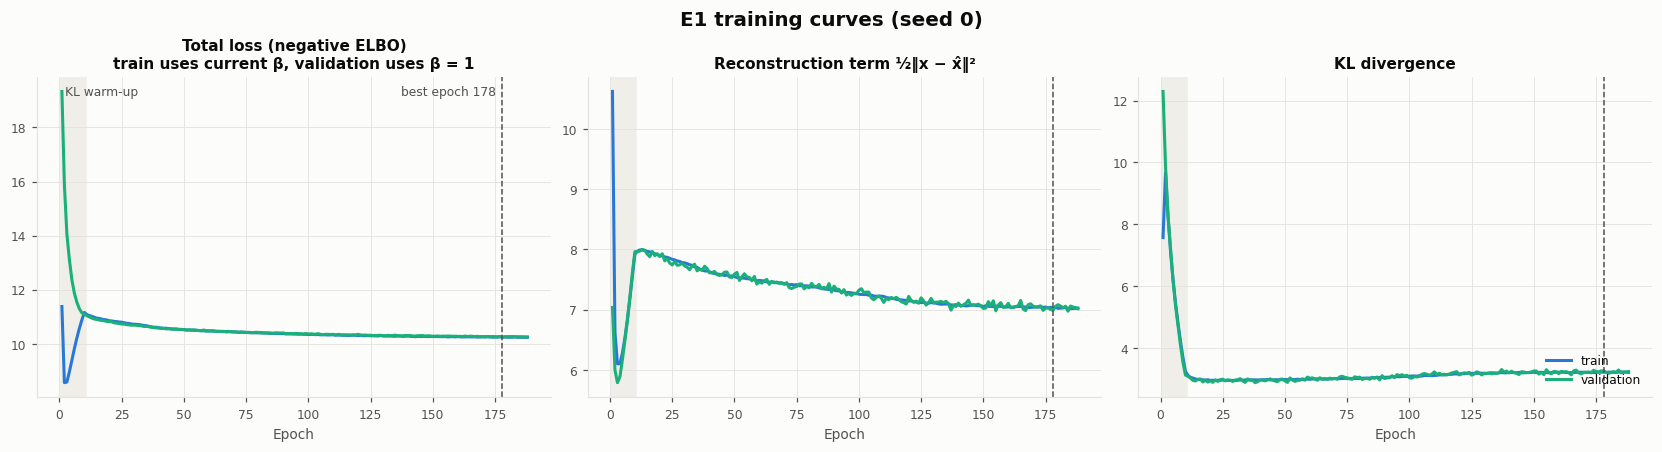

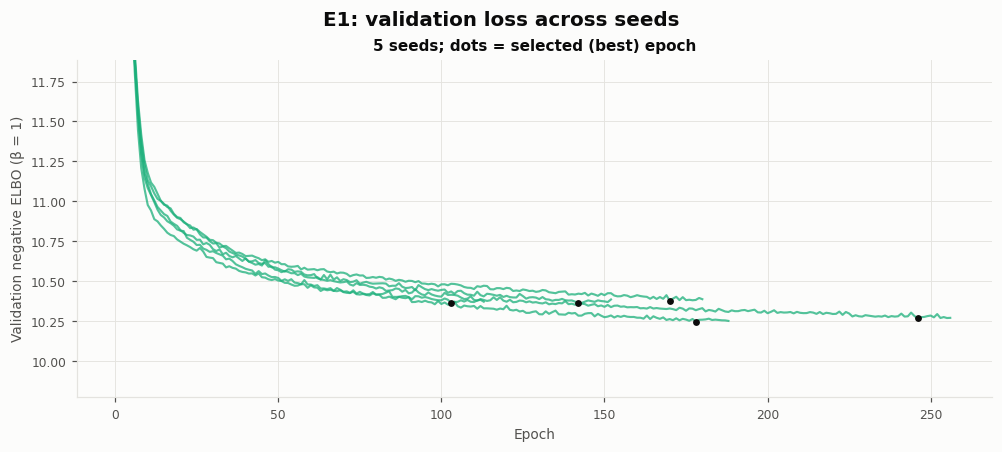

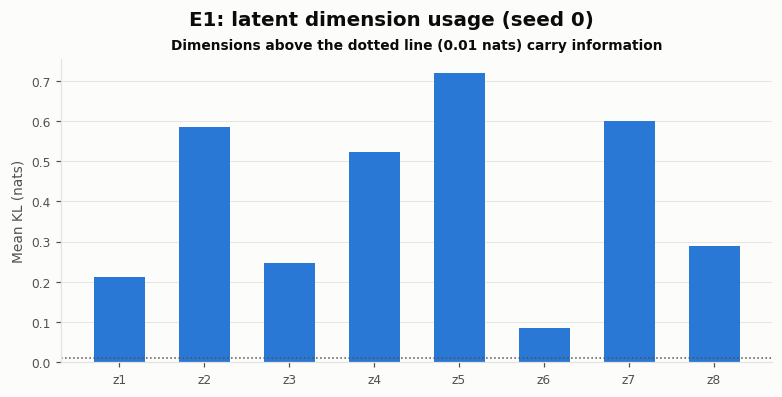

In [6]:
h = pd.read_csv(run_dir(PROJECT_ROOT, "e1", 0) / "history.csv")
best = read_run(run_dir(PROJECT_ROOT, "e1", 0))["meta"]["best_epoch"]
mp.plot_training_curves(h, best, e1_cfg["training"]["kl_warmup_epochs"], "E1 training curves (seed 0)")
plt.show()
histories = {s: pd.read_csv(run_dir(PROJECT_ROOT, "e1", s) / "history.csv") for s in e1_cfg["seeds"]}
bests = {s: read_run(run_dir(PROJECT_ROOT, "e1", s))["meta"]["best_epoch"] for s in e1_cfg["seeds"]}
mp.plot_seed_curves(histories, bests, "E1: validation loss across seeds")
plt.show()
mp.plot_kl_per_dim(np.array(read_run(run_dir(PROJECT_ROOT, "e1", 0))["meta"]["kl_per_latent_dim"]), "E1: latent dimension usage (seed 0)")
plt.show()

## 5. Threshold calibration (no fraud labels, no test data)

**Method:** τ is the 99th percentile of the reconstruction error on the calibration rows. For E1 these are the 42,647 **normal validation** transactions; for E2 they are all 42,721 validation transactions, unlabelled.

**Rationale:**
- The model only knows what normal looks like, so the threshold is set from the normal error distribution.
- The 99th percentile means about 1% of normal traffic is flagged, which is an explicit and interpretable alert budget.
- The fraud labels and the test set play no part. The validation fraud rows are never used.

Other percentiles are evaluated later as a sensitivity analysis only.

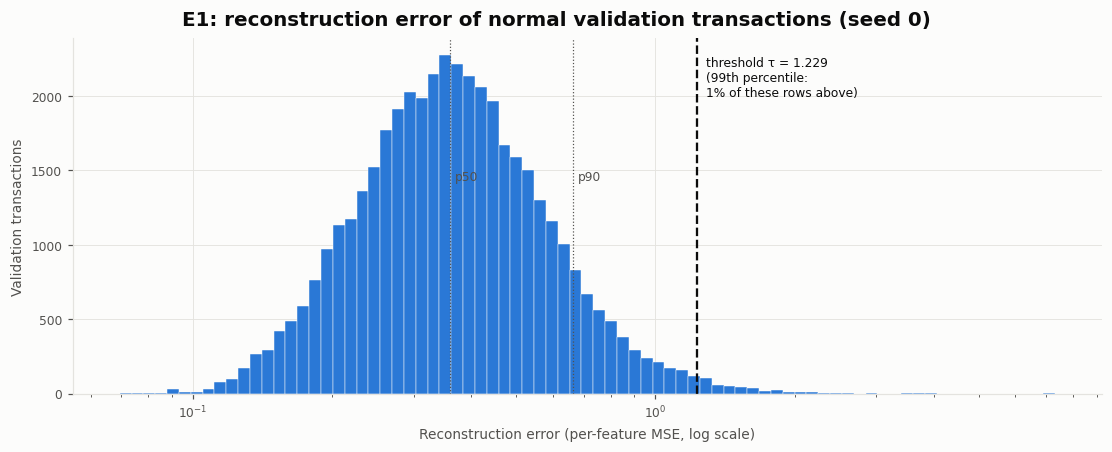

,E1 seed 0
method,validation_percentile
score,recon_mse
percentile,99.0
threshold,1.229167
validation_rows,42647
validation_rows_description,normal validation rows only (E1)
validation_flag_rate,0.010012
fraud_labels_used,False
rationale,tau is the score below which the chosen share ...


In [7]:
r = read_run(run_dir(PROJECT_ROOT, "e1", 0))
mp.plot_validation_scores(r["val_scores"], r["threshold"]["threshold"], r["threshold"]["percentile"],
                          "E1: reconstruction error of normal validation transactions (seed 0)")
plt.show()
pd.Series({k: v for k, v in r["threshold"].items() if k not in ("validation_score_summary",)}).to_frame("E1 seed 0")

In [8]:
runs.groupby("experiment")[["best_epoch", "runtime_s", "best_val_neg_elbo", "val_recon_mse", "threshold"]].agg(["mean", "std"]).round(4)

best_epoch          runtime_s  ... val_recon_mse threshold        
                 mean      std      mean  ...           std      mean     std
experiment                                ...                                
e1              167.8  52.6517     71.92  ...        0.0038    1.2391  0.0258
e2              154.2  40.7394     66.04  ...        0.0085    1.2685  0.0413

[2 rows x 10 columns]